# EDA - OpenAlex OSS corpus

Exploratory analysis of `data/raw/openalex_works.jsonl` (produced by `ingest/fetch_openalex.py`).

Covers: year distribution, primary topic and keyword frequency, language counts,
abstract length, and the share of works with an abstract.

Outputs CSVs to `data/eda/` (gitignored) and PNG charts to `report/figures/` (committed).
Run with: `jupyter nbconvert --execute eval/eda.ipynb`


In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPO = Path.cwd()
if not (REPO / "data").exists() and (REPO.parent / "data").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from ingest.fetch_openalex import API, MAILTO, get, load_api_key

DATA = REPO / "data" / "raw" / "openalex_works.jsonl"
EDA_DIR = REPO / "data" / "eda"
FIG_DIR = REPO / "report" / "figures"
EDA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("repo:", REPO)
print("data:", DATA, "exists:", DATA.exists())


def openalex(filter_, group_by=None, per_page=1):
    params = {"filter": filter_, "per-page": per_page, "mailto": MAILTO}
    key = load_api_key()
    if key:
        params["api_key"] = key
    if group_by:
        params["group_by"] = group_by
        params["per-page"] = 200  # per-page caps how many groups come back
    return get(API, params)


repo: /home/ia/EleventhMarch/5th/Big Data Storage/Project
data: /home/ia/EleventhMarch/5th/Big Data Storage/Project/data/raw/openalex_works.jsonl exists: True


works: 15077
with abstract: 15077 (100.0%)

coverage vs topic-wide:
topic_total            75472
topic_with_abstract    48320
corpus                 15077


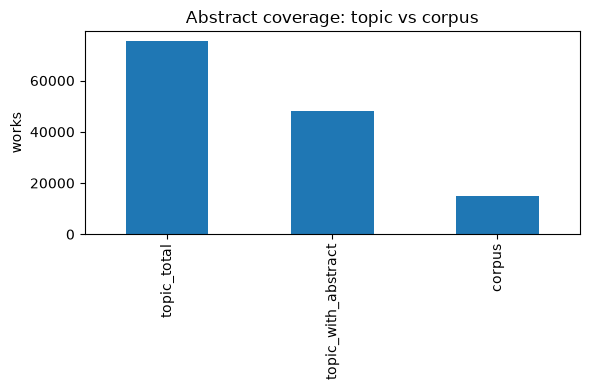

In [2]:
records = []
with open(DATA, encoding="utf-8") as fh:
    for line in fh:
        w = json.loads(line)
        pt = w.get("primary_topic") or {}
        records.append({
            "id": w["id"],
            "year": w.get("publication_year"),
            "language": w.get("language"),
            "type": w.get("type"),
            "primary_topic": pt.get("display_name"),
            "keywords": [k.get("display_name") for k in (w.get("keywords") or [])],
            "abstract": w.get("abstract"),
        })
df = pd.DataFrame(records)
df["abstract_words"] = df["abstract"].fillna("").str.split().str.len()
corpus = len(df)
with_abs = openalex("topics.id:T11675,has_abstract:true")["meta"]["count"]
total = openalex("topics.id:T11675")["meta"]["count"]
counts = pd.Series({"topic_total": total, "topic_with_abstract": with_abs, "corpus": corpus})
counts.to_csv(EDA_DIR / "coverage_counts.csv")
print("works:", corpus)
print("with abstract:", int(df["abstract"].notna().sum()),
      f"({df['abstract'].notna().mean():.1%})")
print("\ncoverage vs topic-wide:")
print(counts.to_string())
fig, ax = plt.subplots(figsize=(6, 4))
counts.plot.bar(ax=ax)
ax.set_title("Abstract coverage: topic vs corpus")
ax.set_ylabel("works")
fig.tight_layout()
fig.savefig(FIG_DIR / "abstract_coverage.png", dpi=120)


## Year distribution

range: 1866 - 2027 | median: 2016
year
2013    720
2014    792
2015    729
2016    747
2017    707
2018    755
2019    807
2020    714
2021    751
2022    617
2023    586
2024    512
2025    625
2026    848
2027      1


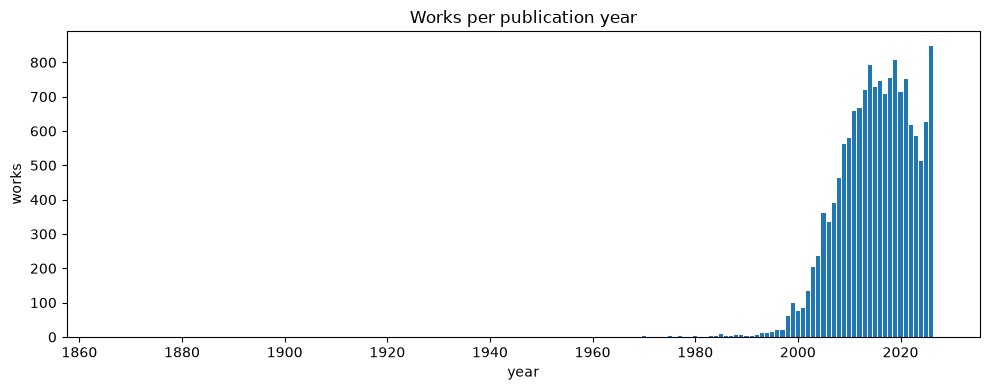

In [3]:
years = df["year"].dropna().astype(int)
year_counts = years.value_counts().sort_index()
year_counts.to_csv(EDA_DIR / "year_counts.csv", header=["count"])
print("range:", years.min(), "-", years.max(), "| median:", int(years.median()))
print(year_counts.tail(15).to_string())
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(year_counts.index, year_counts.values)
ax.set_title("Works per publication year")
ax.set_xlabel("year")
ax.set_ylabel("works")
fig.tight_layout()
fig.savefig(FIG_DIR / "year_distribution.png", dpi=120)


## Primary topic and keyword frequency

distinct primary topics: 427
primary_topic
Open Source Software Innovations                              5978
Software Engineering Techniques and Practices                  884
Software Engineering Research                                  849
Mobile Crowdsensing and Crowdsourcing                          802
Innovation and Knowledge Management                            784
Service and Product Innovation                                 428
FinTech, Crowdfunding, Digital Finance                         356
Open Education and E-Learning                                  325
Innovative Approaches in Technology and Social Development     281
Digital Platforms and Economics                                279

top keywords:
open source software             4160
crowdsourcing                    1505
open innovation                  1442
free and open source software     656
open source communities           561
Linux                             533
free software                     476
softwa

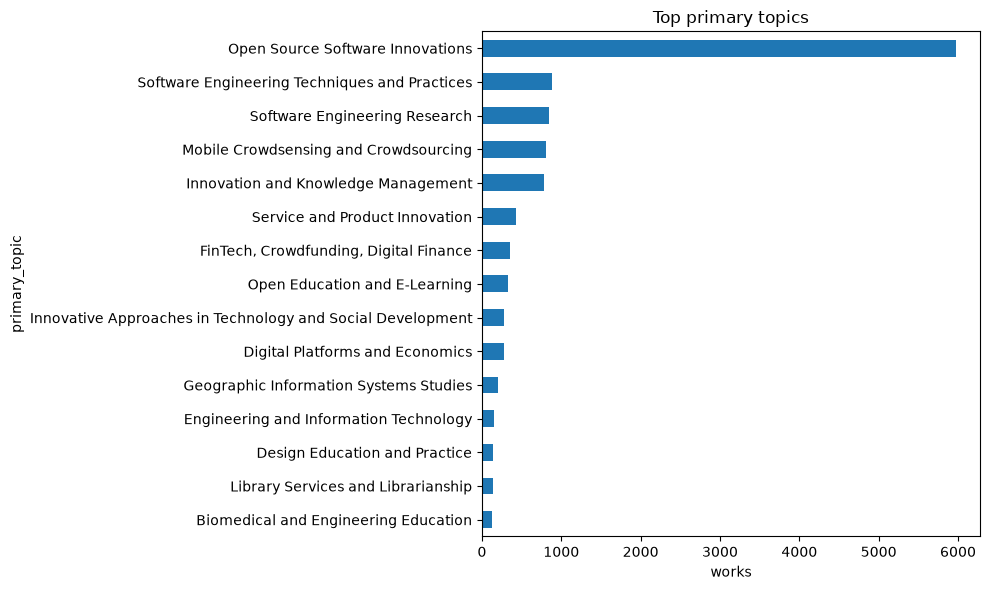

In [4]:
pt_counts = df["primary_topic"].value_counts()
pt_counts.head(20).to_csv(EDA_DIR / "primary_topic_top.csv", header=["count"])
kw_top = pd.Series(Counter(k for ks in df["keywords"] for k in ks)).sort_values(ascending=False)
kw_top.head(30).to_csv(EDA_DIR / "keyword_top.csv", header=["count"])
print("distinct primary topics:", pt_counts.size)
print(pt_counts.head(10).to_string())
print("\ntop keywords:")
print(kw_top.head(10).to_string())
fig, ax = plt.subplots(figsize=(10, 6))
pt_counts.head(15)[::-1].plot.barh(ax=ax)
ax.set_title("Top primary topics")
ax.set_xlabel("works")
fig.tight_layout()
fig.savefig(FIG_DIR / "primary_topics.png", dpi=120)


## Language

language
en    15077


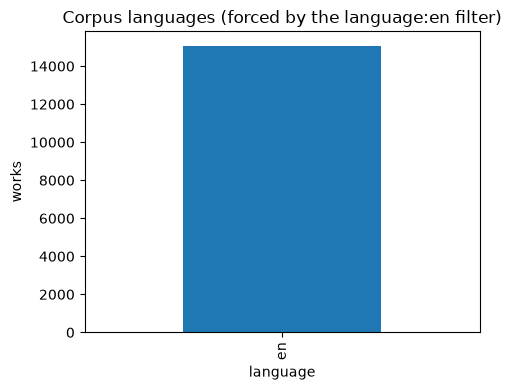

In [5]:
lang_counts = df["language"].fillna("(none)").value_counts()
lang_counts.to_csv(EDA_DIR / "language_counts.csv", header=["count"])
print(lang_counts.to_string())
fig, ax = plt.subplots(figsize=(5, 4))
lang_counts.plot.bar(ax=ax)
ax.set_title("Corpus languages (forced by the language:en filter)")
ax.set_ylabel("works")
fig.tight_layout()
fig.savefig(FIG_DIR / "language_corpus.png", dpi=120)


## Abstract length (words)

works     15077.00000
mean        156.49612
median      146.00000
p10          35.60000
p90         257.00000
p99         560.00000
min           1.00000
max        4027.00000
(-0.001, 50.0]            2089
(50.0, 100.0]             2196
(100.0, 150.0]            3857
(150.0, 200.0]            3287
(200.0, 250.0]            1956
(250.0, 300.0]             870
(300.0, 400.0]             503
(400.0, 500.0]             131
(500.0, 1000.0]            156
(1000.0, 1000000000.0]      32


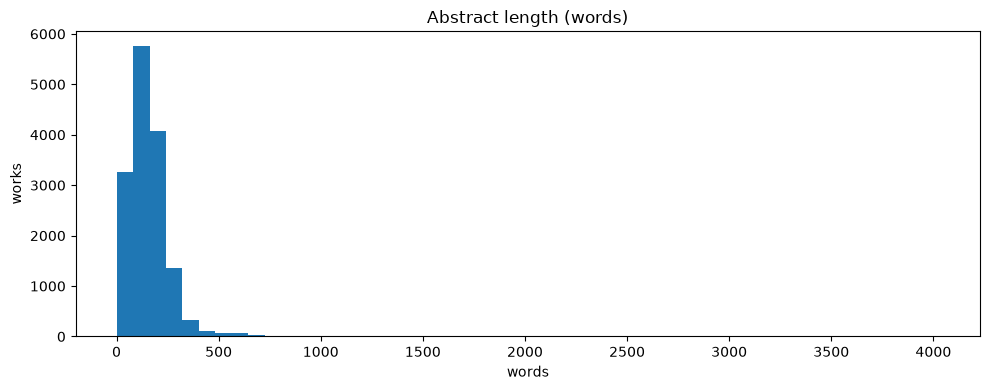

In [6]:
n = df.loc[df["abstract"].notna(), "abstract_words"]
summary = pd.Series({
    "works": len(n),
    "mean": n.mean(),
    "median": n.median(),
    "p10": n.quantile(0.10),
    "p90": n.quantile(0.90),
    "p99": n.quantile(0.99),
    "min": n.min(),
    "max": n.max(),
})
summary.to_csv(EDA_DIR / "abstract_length_summary.csv", header=["value"])
hist = n.value_counts(bins=[0, 50, 100, 150, 200, 250, 300, 400, 500, 1000, 10**9]).sort_index()
hist.to_csv(EDA_DIR / "abstract_length_hist.csv", header=["count"])
print(summary.to_string())
print(hist.to_string())
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(n, bins=50)
ax.set_title("Abstract length (words)")
ax.set_xlabel("words")
ax.set_ylabel("works")
fig.tight_layout()
fig.savefig(FIG_DIR / "abstract_length.png", dpi=120)


## API cross-check (topic-wide)

The corpus was fetched with `has_abstract:true` and `language:en`, so in-corpus coverage is 100% and the language is `en` by construction. These queries show the real topic-wide mix.

                    metric      value
               topic_total 75472.0000
       topic_with_abstract 48320.0000
             corpus_filter 15077.0000
abstract_coverage_of_topic     0.6402
corpus_share_of_abstracted     0.3120

works with abstract / topic total = 64.0%
corpus / abstracted topic works = 31.2%

language mix (topic-wide, top 10):
  language  count
   English  37490
   Spanish   2748
    French   1993
Portuguese   1411
    German   1089
   Chinese    821
  Japanese    359
   Russian    231
   Italian    215
   Swedish    214
english share of abstracted topic works = 77.6%


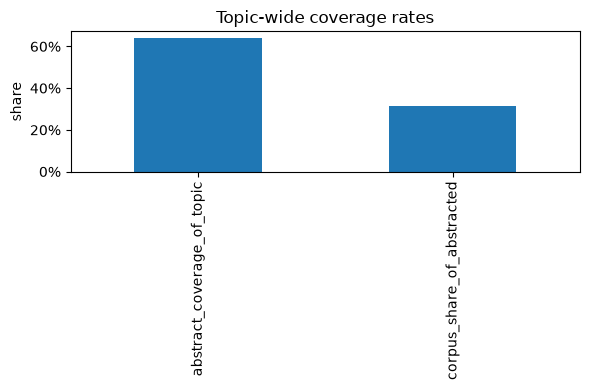

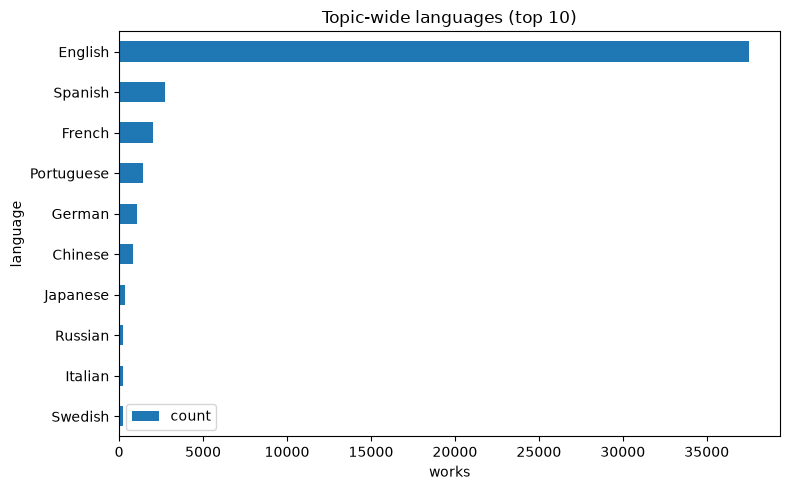

In [7]:
cross = pd.DataFrame([
    {"metric": "topic_total", "value": total},
    {"metric": "topic_with_abstract", "value": with_abs},
    {"metric": "corpus_filter", "value": corpus},
    {"metric": "abstract_coverage_of_topic", "value": round(with_abs / total, 4)},
    {"metric": "corpus_share_of_abstracted", "value": round(corpus / with_abs, 4)},
])
cross.to_csv(EDA_DIR / "api_crosscheck.csv", index=False)
print(cross.to_string(index=False))
print(f"\nworks with abstract / topic total = {with_abs / total:.1%}")
print(f"corpus / abstracted topic works = {corpus / with_abs:.1%}")

rates = pd.Series({
    "abstract_coverage_of_topic": with_abs / total,
    "corpus_share_of_abstracted": corpus / with_abs,
})
fig, ax = plt.subplots(figsize=(6, 4))
rates.plot.bar(ax=ax)
ax.set_title("Topic-wide coverage rates")
ax.set_ylabel("share")
ax.yaxis.set_major_formatter("{x:.0%}")
fig.tight_layout()
fig.savefig(FIG_DIR / "coverage_rates.png", dpi=120)

lang = openalex("topics.id:T11675,has_abstract:true", group_by="language")["group_by"]
lang_df = pd.DataFrame([{"language": g["key_display_name"] or "(none)", "count": g["count"]} for g in lang])
lang_df.to_csv(EDA_DIR / "api_language_group.csv", index=False)
print("\nlanguage mix (topic-wide, top 10):")
print(lang_df.head(10).to_string(index=False))
english = lang_df.loc[lang_df["language"] == "English", "count"].sum()
print(f"english share of abstracted topic works = {english / with_abs:.1%}")

fig, ax = plt.subplots(figsize=(8, 5))
lang_df.head(10)[::-1].plot.barh(ax=ax, x="language", y="count")
ax.set_title("Topic-wide languages (top 10)")
ax.set_xlabel("works")
fig.tight_layout()
fig.savefig(FIG_DIR / "language_topic_wide.png", dpi=120)

yr = openalex("topics.id:T11675,has_abstract:true", group_by="publication_year")["group_by"]
yr_df = pd.DataFrame([{"year": g["key"], "count": g["count"]} for g in yr]).sort_values("year")
yr_df.to_csv(EDA_DIR / "api_year_group.csv", index=False)


## Notes for BAB 3

- In-corpus metrics are shaped by the fetch filter (article, english, has abstract); the API cross-check gives the honest coverage figure.
- The topic holds many non-English works; restricting to english is a stated limitation.
- Abstract-length outliers and the year skew are corpus limitations worth stating explicitly.
- CSVs in `data/eda/` feed the experiment tables; PNGs in `report/figures/` feed the report.
